## 语义分块简介  
文本分块是检索增强生成（RAG）中的一个重要步骤，其中大段文本被划分为有意义的片段，以提高检索准确性。  
与固定长度的分块不同，语义分块基于句子之间的内容相似性来划分文本。

### 断点方法：
- **百分位法（Percentile）**：找到所有相似度差异的第X百分位，并在下降幅度大于该值的位置进行分块。
- **标准差法（Standard Deviation）**：在相似度低于平均值X个标准差的位置进行分块。
- **四分位距法（Interquartile Range, IQR）**：使用四分位距（Q3 - Q1）来确定分块点。

本笔记本实现了基于 **百分位法** 的语义分块，并对样本文本评估其性能。

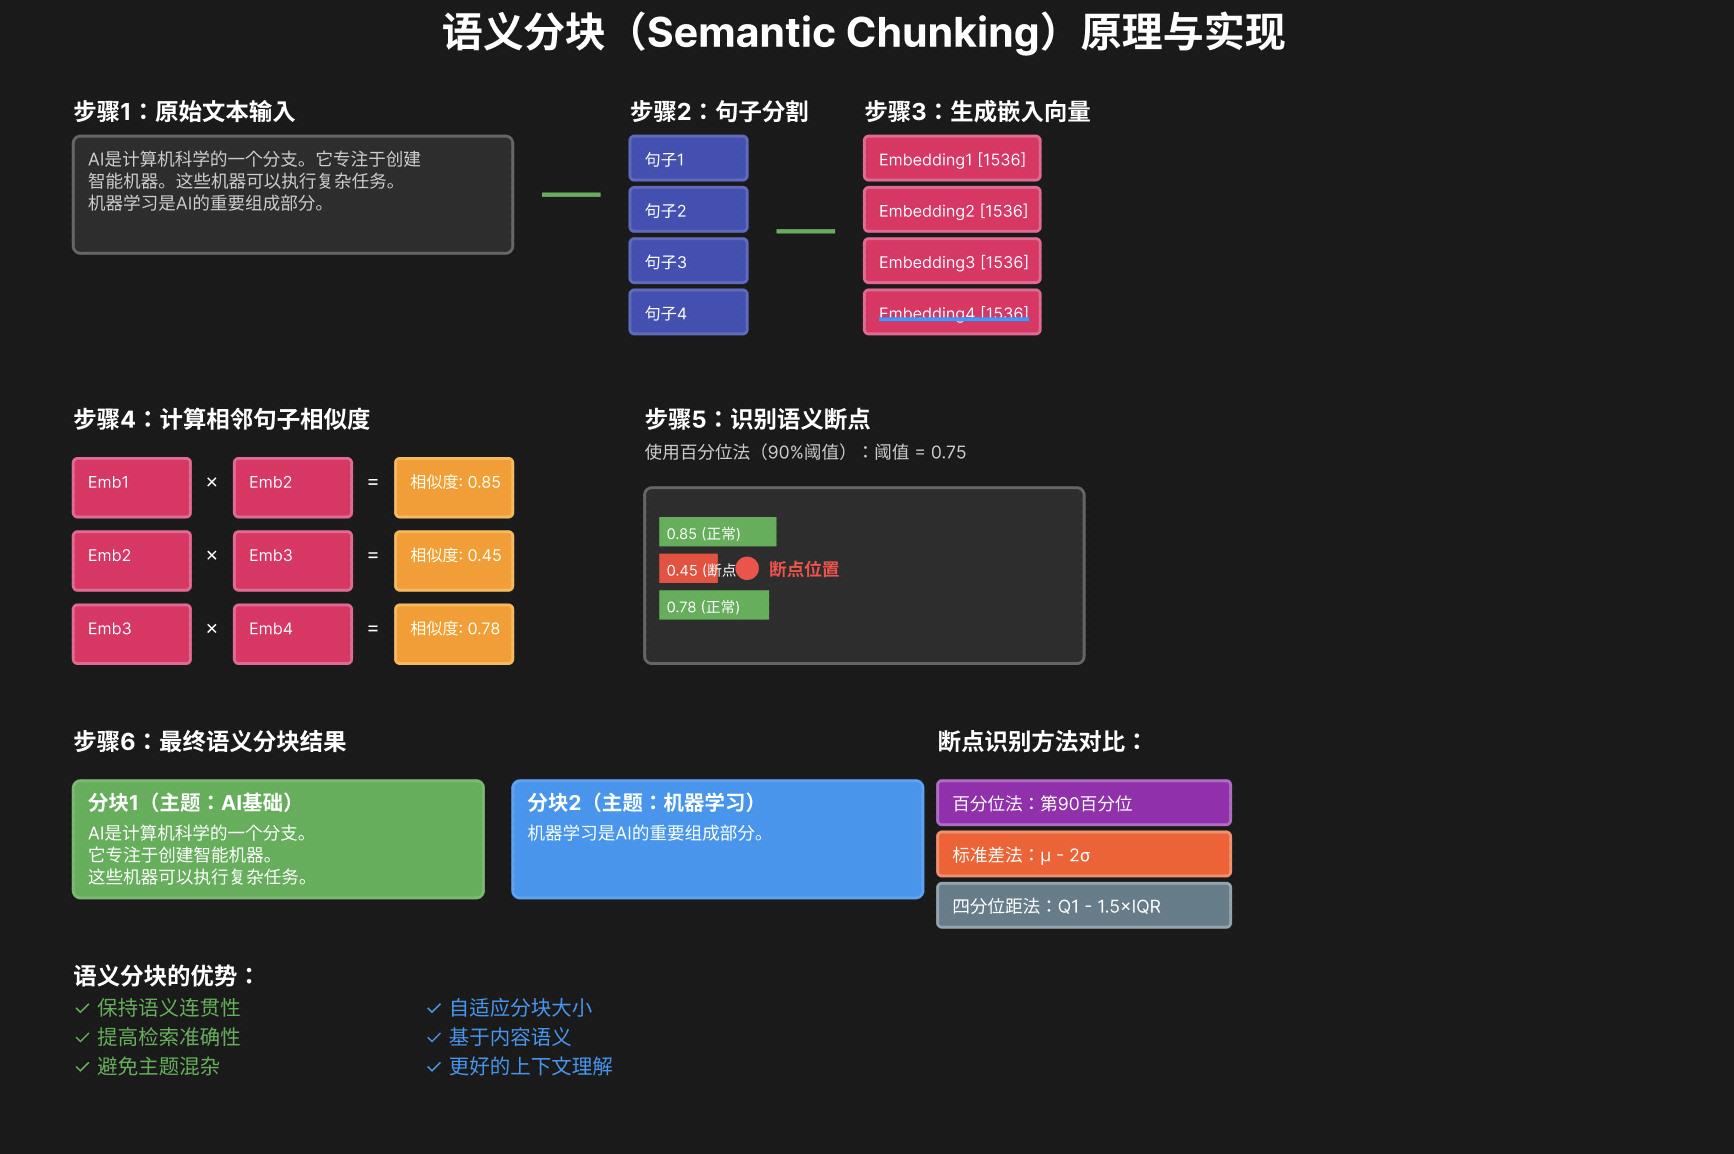

## 环境设置  
我们首先导入必要的库。

In [1]:
import fitz  # PyMuPDF库，用于处理PDF文件
import os  # 操作系统相关功能
import numpy as np  # NumPy库，用于数值计算
import json  # JSON数据处理
from openai import OpenAI  # OpenAI API客户端# generated: lpf2-00Wac lpf2-0dZ82


## 从PDF文件中提取文本  
为了实现RAG（Retrieval-Augmented Generation，检索增强生成），我们首先需要一个文本数据源。在此情况下，我们使用PyMuPDF库从PDF文件中提取文本。

In [2]:
# checksum: lpf2-01Ub7 lpf2-0eZ07
def extract_text_from_pdf(pdf_path):
    """
    从PDF文件中提取文本。

    参数:
    pdf_path (str): PDF文件的路径。

    返回:
    str: 从PDF中提取的文本。
    """
    # 打开PDF文件
    mypdf = fitz.open(pdf_path)
    all_text = ""  # 初始化一个空字符串用于存储提取的文本
    
    # 遍历PDF中的每一页
    for page in mypdf:
        # 从当前页提取文本并添加间距
        all_text += page.get_text("text") + " "

    # 返回提取的文本，去除首尾空白字符
    return all_text.strip()

# 定义PDF文件的路径
pdf_path = "data/AI_Information.pdf"

# 从PDF文件中提取文本
extracted_text = extract_text_from_pdf(pdf_path)

# 打印提取文本的前500个字符
print(extracted_text[:500])

Understanding Artificial Intelligence 
Chapter 1: Introduction to Artificial Intelligence 
Artificial intelligence (AI) refers to the ability of a digital computer or computer-controlled robot 
to perform tasks commonly associated with intelligent beings. The term is frequently applied to 
the project of developing systems endowed with the intellectual processes characteristic of 
humans, such as the ability to reason, discover meaning, generalize, or learn from past 
experience. Over the past f


## 初始化OpenAI API客户端  
我们初始化OpenAI客户端以生成嵌入向量（embeddings）和回复。

In [3]:
from dotenv import load_dotenv
import os

# cache: lpf2-02Ga6 lpf2-0fCf0
load_dotenv()  # 加载.env文件（在 .env 里填写 DASHSCOPE_API_KEY）

# 模型调用改为阿里云百炼（OpenAI 兼容接口）：对话模型用 qwen-flash，向量模型用 text-embedding-v4
client = OpenAI(
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key=os.getenv("DASHSCOPE_API_KEY")  # 从环境变量中获取 API 密钥，不要写进代码或打印
)

# 百炼的 text-embedding-v4 单次最多 10 条文本：这里把 client.embeddings.create 包一层自动分批，
# 返回结构与 OpenAI 相同，后面的代码不用改
_embeddings_create = client.embeddings.create
def _batched_embeddings_create(model, input, **kwargs):
    if isinstance(input, str) or len(input) <= 10:
        return _embeddings_create(model=model, input=input, **kwargs)
    merged = None
    for i in range(0, len(input), 10):
        resp = _embeddings_create(model=model, input=input[i:i + 10], **kwargs)
        if merged is None:
            merged = resp
        else:
            merged.data.extend(resp.data)
    for idx, item in enumerate(merged.data):
        item.index = idx
    return merged
client.embeddings.create = _batched_embeddings_create


## 创建句子级嵌入
我们将文本拆分为句子并生成嵌入。

In [4]:
# checksum: lpf2-03Sec lpf2-1078c
def get_embedding(text, model="text-embedding-v4"):
    """
    使用指定模型为给定文本生成嵌入向量。

    参数:
    text (str): 输入文本。
    model (str): 嵌入模型名称。

    返回:
    np.ndarray: 嵌入向量。
    """
    response = client.embeddings.create(model=model, input=text)
    return np.array(response.data[0].embedding)

# 将文本按句子分割（基本分割）
sentences = extracted_text.split(". ")

# 为每个句子生成嵌入向量
embeddings = [get_embedding(sentence) for sentence in sentences]

print(f"Generated {len(embeddings)} sentence embeddings.")

Generated 257 sentence embeddings.


## 计算相似性差异  
我们计算连续句子之间的余弦相似度。

In [5]:
# cache: lpf2-04Q45 lpf2-11Sfa
def cosine_similarity(vec1, vec2):
    """
    计算两个向量之间的余弦相似度。

    参数:
    vec1 (np.ndarray): 第一个向量。
    vec2 (np.ndarray): 第二个向量。

    返回:
    float: 余弦相似度。
    """
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

# 计算连续句子之间的相似度
similarities = [cosine_similarity(embeddings[i], embeddings[i + 1]) for i in range(len(embeddings) - 1)]

## 实现语义分块
我们实现了三种用于确定断点的方法。

In [6]:
# checksum: lpf2-05G23 lpf2-12F2c
def compute_breakpoints(similarities, method="percentile", threshold=90):
    """
    根据相似度下降计算分块断点。

    参数:
    similarities (List[float]): 句子之间的相似度分数列表。
    method (str): 'percentile', 'standard_deviation' 或 'interquartile'。
    threshold (float): 阈值（对于 'percentile' 是百分位数，对于 'standard_deviation' 是标准差的数量）。

    返回:
    List[int]: 应该发生分块分裂的索引位置列表。
    """
    # 根据所选方法确定阈值
    if method == "percentile":
        # 计算相似度分数的第X百分位
        threshold_value = np.percentile(similarities, threshold)
    elif method == "standard_deviation":
        # 计算相似度分数的平均值和标准差
        mean = np.mean(similarities)
        std_dev = np.std(similarities)
        # 将阈值设置为平均值减去X个标准差
        threshold_value = mean - (threshold * std_dev)
    elif method == "interquartile":
        # 计算第一和第三四分位数（Q1 和 Q3）
        q1, q3 = np.percentile(similarities, [25, 75])
        # 使用IQR规则设置阈值以检测异常值
        threshold_value = q1 - 1.5 * (q3 - q1)
    else:
        # 如果提供了无效方法，则引发错误
        raise ValueError("Invalid method. Choose 'percentile', 'standard_deviation', or 'interquartile'.")

    # 找出相似度低于阈值的位置索引
    return [i for i, sim in enumerate(similarities) if sim < threshold_value]

# 使用百分位法并设置阈值为90计算断点
breakpoints = compute_breakpoints(similarities, method="percentile", threshold=90)

## 将文本分割为语义块  
我们根据计算出的断点来分割文本。

In [7]:
# revision: lpf2-06Y19 lpf2-13T53
def split_into_chunks(sentences, breakpoints):
    """
    将句子分割为语义块。

    参数:
    sentences (List[str]): 句子列表。
    breakpoints (List[int]): 应该发生分割的索引位置。

    返回:
    List[str]: 文本块列表。
    """
    chunks = []  # 初始化一个空列表来存储块
    start = 0  # 初始化起始索引

    # 遍历每个断点以创建块
    for bp in breakpoints:
        # 将从起始到当前断点的句子片段加入块中
        chunks.append(". ".join(sentences[start:bp + 1]) + ".")
        start = bp + 1  # 更新起始索引到断点后的下一个句子

    # 将剩余的句子作为最后一个块加入
    chunks.append(". ".join(sentences[start:]))
    return chunks  # 返回块列表

# 使用 split_into_chunks 函数创建块
text_chunks = split_into_chunks(sentences, breakpoints)

# 打印生成的块数量
print(f"Number of semantic chunks: {len(text_chunks)}")

# 打印第一个块以验证结果
print("\nFirst text chunk:")
print(text_chunks[0])

Number of semantic chunks: 231

First text chunk:
Understanding Artificial Intelligence 
Chapter 1: Introduction to Artificial Intelligence 
Artificial intelligence (AI) refers to the ability of a digital computer or computer-controlled robot 
to perform tasks commonly associated with intelligent beings.


## 创建语义片段的嵌入  
我们为每个片段创建嵌入，以便后续检索。

In [8]:
# checksum: lpf2-07Ne9 lpf2-14Ad9
def create_embeddings(text_chunks):
    """
    为每个文本块创建嵌入。

    参数:
    text_chunks (List[str]): 文本块的列表。

    返回:
    List[np.ndarray]: 嵌入向量的列表。
    """
    # 使用 get_embedding 函数为每个文本块生成嵌入
    return [get_embedding(chunk) for chunk in text_chunks]

# 使用 create_embeddings 函数创建分块嵌入
chunk_embeddings = create_embeddings(text_chunks)

## 执行语义搜索  
我们通过余弦相似度来检索最相关的片段。

In [9]:
# checksum: lpf2-08Jcd lpf2-15H4a
def semantic_search(query, text_chunks, chunk_embeddings, k=5):
    """
    查找与查询最相关的文本片段。

    参数:
    query (str): 搜索查询。
    text_chunks (List[str]): 文本片段列表。
    chunk_embeddings (List[np.ndarray]): 文本片段嵌入列表。
    k (int): 返回的最相关结果数量。

    返回:
    List[str]: 前k个最相关的文本片段。
    """
    # 为查询生成一个嵌入向量
    query_embedding = get_embedding(query)
    
    # 计算查询嵌入与每个片段嵌入之间的余弦相似度
    similarities = [cosine_similarity(query_embedding, emb) for emb in chunk_embeddings]
    
    # 获取最相似的k个片段的索引
    top_indices = np.argsort(similarities)[-k:][::-1]
    
    # 返回前k个最相关的文本片段
    return [text_chunks[i] for i in top_indices]

In [10]:
# 从JSON文件中加载验证数据  
# checksum: lpf2-09A72 lpf2-16Sff
with open('data/val.json') as f:  
    data = json.load(f)  

# 从验证数据中提取第一个查询  
query = data[0]['question']  

# 获取最相关的前2个片段  
top_chunks = semantic_search(query, text_chunks, chunk_embeddings, k=2)  

# 打印查询  
print(f"Query: {query}")  

# 打印最相关的前2个文本片段  
for i, chunk in enumerate(top_chunks):  
    print(f"Context {i+1}:\n{chunk}\n{'='*40}")

Query: What is 'Explainable AI' and why is it considered important?
Context 1:

Explainable AI (XAI) 
Explainable AI (XAI) aims to make AI systems more transparent and understandable. Research in 
XAI focuses on developing methods for explaining AI decisions, enhancing trust, and improving 
accountability.
Context 2:
Key trends and areas of development include: 
Explainable AI (XAI) 
Explainable AI (XAI) aims to make AI systems more transparent and understandable. XAI 
techniques are being developed to provide insights into how AI models make decisions, 
enhancing trust and accountability.


## 基于检索块生成回复

In [11]:
# 定义AI助手的系统提示
# generated: lpf2-0aZdb lpf2-1761f
system_prompt = "You are an AI assistant that strictly answers based on the given context. If the answer cannot be derived directly from the provided context, respond with: 'I do not have enough information to answer that.'"

def generate_response(system_prompt, user_message, model="qwen-flash"):
    """
    根据系统提示和用户消息生成AI模型的回复。

    参数:
    system_prompt (str): 用于指导AI行为的系统提示。
    user_message (str): 用户的消息或查询。
    model (str): 用于生成回复的模型。

    返回:
    dict: AI模型的回复。
    """
    response = client.chat.completions.create(
        model=model,
        temperature=0,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_message}
        ]
    )
    return response

# 根据顶级片段创建用户提示
user_prompt = "\n".join([f"Context {i + 1}:\n{chunk}\n=====================================\n" for i, chunk in enumerate(top_chunks)])
user_prompt = f"{user_prompt}\nQuestion: {query}"

# 生成AI回复
ai_response = generate_response(system_prompt, user_prompt)
print(ai_response.choices[0].message.content)

Explainable AI (XAI) refers to methods and techniques that make the decisions and behaviors of artificial intelligence systems transparent and understandable to humans. It is considered important because it enhances trust in AI systems, improves accountability, and helps users understand how and why AI models arrive at specific decisions. This transparency is crucial for ethical use, regulatory compliance, and fostering user confidence in AI applications.


## 评估AI回复
我们将AI的回复与预期答案进行比较，并分配一个分数。

In [12]:
# 定义评估系统的系统提示
# cache: lpf2-0bI32 lpf2-184b6
evaluate_system_prompt = "You are an intelligent evaluation system tasked with assessing the AI assistant's responses. If the AI assistant's response is very close to the true response, assign a score of 1. If the response is incorrect or unsatisfactory in relation to the true response, assign a score of 0. If the response is partially aligned with the true response, assign a score of 0.5."

# 通过组合用户查询、AI回复、真实回复和评估系统提示创建评估提示
evaluation_prompt = f"User Query: {query}\nAI Response:\n{ai_response.choices[0].message.content}\nTrue Response: {data[0]['ideal_answer']}\n{evaluate_system_prompt}"

# 使用评估系统提示和评估提示生成评估回复
evaluation_response = generate_response(evaluate_system_prompt, evaluation_prompt)

# 打印评估回复
print(evaluation_response.choices[0].message.content)

Score: 1

The AI assistant's response is very close to the true response. It accurately defines Explainable AI (XAI) as methods that make AI decisions transparent and understandable, and correctly identifies key reasons for its importance—trust, accountability, and understanding of decision-making. While the assistant adds slightly more detail (e.g., regulatory compliance, ethical use, user confidence), these are consistent with and supportive of the core points in the true response. There is no inaccuracy or misrepresentation, and the essence of the true response is fully captured.


In [ ]:
# cache: lpf2-0cW08 lpf2-19Y64
